# Fase 3 — Preparación y modelado de datos

En este notebook se:
1. Limpian los datos aplicando reglas de negocio documentadas.
2. Transforman y derivan nuevas variables (distancia, atributos de tiempo, tipo de viaje).
3. Seleccionan las variables del análisis.
4. Definen dimensiones y métricas y se construye un **modelo estrella** para Power BI.

In [1]:
import sys
from pathlib import Path

sys.path.append(str(Path.cwd().parent))

import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

from src.cleaning import clean_data
from src.config import FIGURES_DIR, PROCESSED_DIR, REPORTS_DIR
from src.data_loader import load_raw_data
from src.features import build_features
from src.modeling import build_star_schema

sns.set_theme(style="whitegrid", palette="deep")

## 1. Limpieza de datos

| Regla | Justificación |
|-------|---------------|
| Eliminar nulos | Solo existe un registro con coordenadas de destino nulas; no se puede calcular la distancia. |
| Eliminar claves duplicadas | Cada `key` identifica un único viaje. |
| Tarifa entre 2,5 y 250 USD | 2,5 USD es la tarifa mínima de NYC; valores negativos o extremos son errores de registro. |
| Pasajeros entre 1 y 6 | Un viaje sin pasajeros o con más de 6 no es posible en un vehículo estándar. |
| Coordenadas dentro de NYC | Hay coordenadas en (0, 0) o fuera de la ciudad que no corresponden a viajes reales. |
| Distancia entre 0,1 y 100 km | Distancias nulas (origen = destino) o desproporcionadas indican errores de GPS. |

In [2]:
raw = load_raw_data()
clean, bitacora = clean_data(raw)
bitacora

,regla,eliminados,restantes,pct_eliminado
0,Registros originales,0,200000,0.00
1,Valores nulos,1,199999,0.00
2,Claves duplicadas,0,199999,0.00
3,"Tarifa fuera de [2.5, 250] USD",28,199971,0.01
4,"Pasajeros fuera de [1, 6]",709,199262,0.35
5,Coordenadas fuera de NYC,4376,194886,2.19
6,"Distancia fuera de [0.1, 100] km",3110,191776,1.56


In [3]:
print(f"Registros conservados: {len(clean):,} de {len(raw):,} "
      f"({len(clean) / len(raw):.1%})")
bitacora.to_csv(REPORTS_DIR / "bitacora_limpieza.csv", index=False)

Registros conservados: 191,776 de 200,000 (95.9%)


## 2. Transformación y variables derivadas

- `distancia_km`: distancia de Haversine entre origen y destino.
- `tarifa_por_km`: tarifa dividida por la distancia.
- `fecha_local`, `anio`, `mes`, `trimestre`, `dia_semana`, `hora`: derivados de `pickup_datetime`, que ya
  está en hora local de Nueva York aunque tenga el sufijo "UTC" (ver conclusiones del notebook 01).
- `franja_horaria`: Madrugada (0-5 h), Mañana (6-11 h), Tarde (12-17 h), Noche (18-23 h).
- `es_hora_pico`: días hábiles de 7 a 9 h y de 16 a 19 h.
- `es_fin_de_semana`, `categoria_distancia`, `aeropuerto` (JFK, LGA, EWR a menos de 2 km).

In [4]:
df = build_features(clean)
df.head()

,key,fare_amount,pickup_datetime,pickup_longitude,pickup_latitude,dropoff_longitude,dropoff_latitude,passenger_count,fecha_local,fecha,...,dia_semana,hora,franja_horaria,es_fin_de_semana,es_hora_pico,distancia_km,tarifa_por_km,categoria_distancia,aeropuerto,es_aeropuerto
0,2015-05-07 19:52:06.0000003,7.5,2015-05-07 19:52:06,-73.999817,40.738354,-73.999512,40.723217,1,2015-05-07 19:52:06,2015-05-07,...,Jueves,19,Noche,False,True,1.683323,4.455474,0-2 km,Ninguno,False
1,2009-07-17 20:04:56.0000002,7.7,2009-07-17 20:04:56,-73.994355,40.728225,-73.994710,40.750325,1,2009-07-17 20:04:56,2009-07-17,...,Viernes,20,Noche,False,False,2.457590,3.133151,2-5 km,Ninguno,False
2,2009-08-24 21:45:00.00000061,12.9,2009-08-24 21:45:00,-74.005043,40.740770,-73.962565,40.772647,1,2009-08-24 21:45:00,2009-08-24,...,Lunes,21,Noche,False,False,5.036377,2.561365,5-10 km,Ninguno,False
3,2009-06-26 08:22:21.0000001,5.3,2009-06-26 08:22:21,-73.976124,40.790844,-73.965316,40.803349,3,2009-06-26 08:22:21,2009-06-26,...,Viernes,8,Mañana,False,True,1.661683,3.189536,0-2 km,Ninguno,False
4,2014-08-28 17:47:00.000000188,16.0,2014-08-28 17:47:00,-73.925023,40.744085,-73.973082,40.761247,5,2014-08-28 17:47:00,2014-08-28,...,Jueves,17,Tarde,False,True,4.475450,3.575060,2-5 km,Ninguno,False


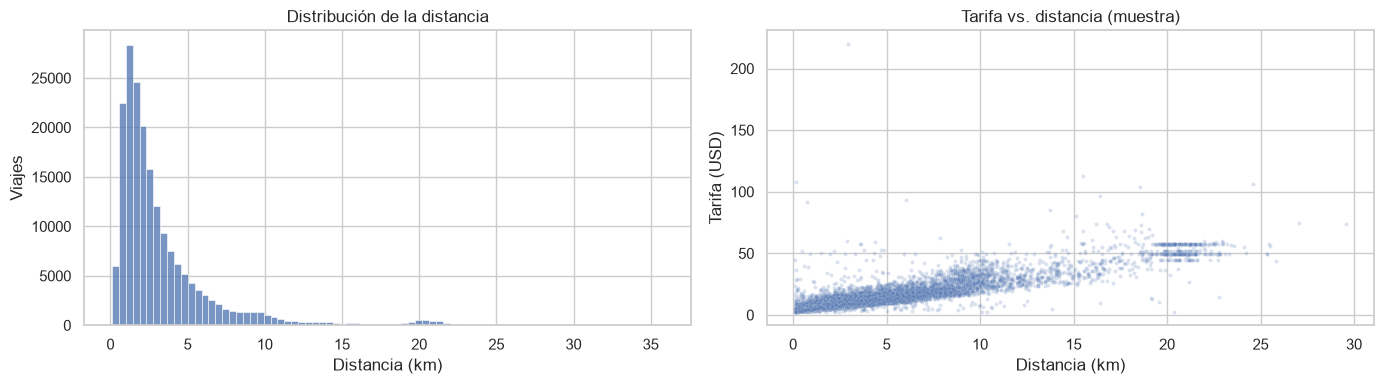

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
sns.histplot(df["distancia_km"], bins=80, ax=axes[0])
axes[0].set(title="Distribución de la distancia", xlabel="Distancia (km)", ylabel="Viajes")
muestra = df.sample(min(len(df), 20_000), random_state=42)
sns.scatterplot(data=muestra, x="distancia_km", y="fare_amount", alpha=0.2, s=8, ax=axes[1])
axes[1].set(title="Tarifa vs. distancia (muestra)", xlabel="Distancia (km)", ylabel="Tarifa (USD)")
plt.tight_layout()
plt.savefig(FIGURES_DIR / "02_distancia_tarifa.png", dpi=120)
plt.show()

In [6]:
df[["fare_amount", "distancia_km", "tarifa_por_km", "passenger_count"]].describe().T

,count,mean,std,min,25%,50%,75%,max
fare_amount,191776.0,11.298550,9.353565,2.500000,6.000000,8.500000,12.500000,220.000000
distancia_km,191776.0,3.365290,3.571358,0.100227,1.294777,2.192351,3.954529,35.825692
tarifa_por_km,191776.0,4.573870,6.911214,0.122807,2.965823,3.811122,5.020318,890.509089
passenger_count,191776.0,1.690639,1.305936,1.000000,1.000000,1.000000,2.000000,6.000000


In [7]:
df["aeropuerto"].value_counts().to_frame("viajes")

,viajes
aeropuerto,
Ninguno,181197
LGA,6357
JFK,3959
EWR,263


## 3. Selección de variables

Se descartan `key` (identificador sin valor analítico, se reemplaza por `id_viaje`) y `pickup_datetime`
(se reemplaza por `fecha_local`). Se conservan las coordenadas para el mapa del dashboard.

In [8]:
analisis_cols = [
    "fare_amount", "distancia_km", "tarifa_por_km", "passenger_count",
    "fecha_local", "fecha", "anio", "mes", "trimestre", "dia_semana_num", "dia_semana",
    "hora", "franja_horaria", "es_fin_de_semana", "es_hora_pico",
    "categoria_distancia", "aeropuerto", "es_aeropuerto",
    "pickup_latitude", "pickup_longitude", "dropoff_latitude", "dropoff_longitude",
]
df = df[analisis_cols]
df.to_csv(PROCESSED_DIR / "uber_clean.csv", index=False)
print(f"Dataset limpio guardado: {df.shape}")

Dataset limpio guardado: (191776, 22)


## 4. Dimensiones, métricas y modelo estrella

**Métricas (hechos):** tarifa (`fare_amount`), distancia (`distancia_km`), tarifa por km, pasajeros y
conteo de viajes.

**Dimensiones:**
- `dim_fecha`: año, trimestre, mes, día de la semana, fin de semana.
- `dim_hora`: hora, franja horaria, rango pico.
- Atributos degenerados en la tabla de hechos: categoría de distancia, aeropuerto, hora pico.

```
           dim_fecha (id_fecha)
                   │ 1
                   │
                   ▼ *
             fact_viajes ◄──────── dim_hora (hora)
                         *       1
```

In [9]:
tablas = build_star_schema(df)
for nombre, tabla in tablas.items():
    tabla.to_csv(PROCESSED_DIR / f"{nombre}.csv", index=False)
    print(f"{nombre}: {tabla.shape}")

fact_viajes: (191776, 16)
dim_fecha: (2372, 10)
dim_hora: (24, 4)


In [10]:
tablas["dim_fecha"].head()

,id_fecha,fecha,anio,trimestre,mes,nombre_mes,anio_mes,dia_semana_num,dia_semana,es_fin_de_semana
0,20090101,2009-01-01,2009,1,1,Enero,2009-01,4,Jueves,False
1,20090102,2009-01-02,2009,1,1,Enero,2009-01,5,Viernes,False
2,20090103,2009-01-03,2009,1,1,Enero,2009-01,6,Sábado,True
3,20090104,2009-01-04,2009,1,1,Enero,2009-01,7,Domingo,True
4,20090105,2009-01-05,2009,1,1,Enero,2009-01,1,Lunes,False


## 5. Conclusiones de la preparación

- La bitácora (`reports/bitacora_limpieza.csv`) documenta cuántos registros eliminó cada regla.
- El dataset limpio (`data/processed/uber_clean.csv`) es la base de las pruebas de hipótesis y los KPIs.
- Las tablas `fact_viajes`, `dim_fecha` y `dim_hora` se cargan en Power BI para construir el dashboard.